In [1]:
import sys, os, datetime, importlib, tqdm

import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

import torchvision
read = torchvision.datasets.CIFAR10(root='ds_CIFAR10', train=True, download=False)
read = torch.as_tensor(read.data[:200]).clone()

epoch 999 - lr : 7.608131805426149e-06 - loss : 207.55126953125: 100%|██████████████| 1000/1000 [08:12<00:00,  2.03it/s]

tensor(207.5513, device='cuda:0')


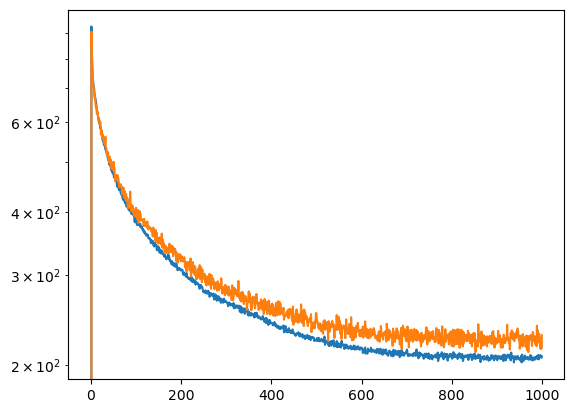

In [151]:
import nn_util; importlib.reload(nn_util)
import nn_tf; importlib.reload(nn_tf)
import nn_reg; importlib.reload(nn_reg)

feed = read[:,:16,:16,0].to(torch.float32)/255
feed = feed.flatten(1).cuda()[:,None,:]

#model = nn_ebm.dynEBAM(train.flatten(1).shape[-1], 128, lr=0.007, r_sigma=1e-4, dist=nn_ebm.dist_dp).to(torch.float32)
model = nn_tf.r2PA_Transformer(h=16, c=1, dim=feed.shape[-1], hdim=32, layers=12, activation='sigmoid', is_residual=False)
wrapper = nn_reg.VMWrapper(model, feed.shape[-1], n=32, T=1).to('cuda', torch.float32)

# optimizer
loss_hist, v_loss_hist = [0], [0]
opt = torch.optim.AdamW(wrapper.parameters(), lr=0.0025, fused=True)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=10, factor=0.9)
d_train, d_valid = feed[:-feed.shape[0]//10], feed[-feed.shape[0]//10:]
# loop
t_loop = tqdm.tqdm(range(1000))
for i in t_loop:
    opt.zero_grad()
    loss    = wrapper.train(d_train)
    v_loss  = wrapper.train(d_valid, do_backprop=False).detach()
    opt.step(); sched.step(v_loss)
    v_loss_hist.append(v_loss.item()); loss_hist.append(loss.detach().item())
    t_loop.set_description(f'epoch {i} - lr : {opt.param_groups[0]['lr']} - loss : {loss_hist[-1]}')
print(loss)
plt.plot(loss_hist); plt.plot(v_loss_hist); plt.yscale('log'); plt.show()

tensor(0.0936) tensor(2.4374)


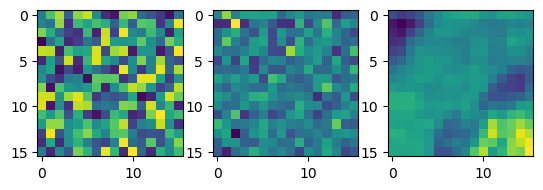

tensor(0.1014) tensor(2.4491)


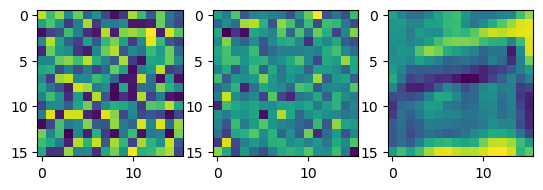

tensor(0.2185) tensor(2.7738)


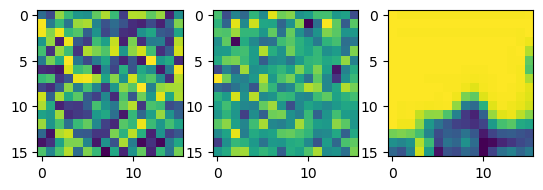

tensor(0.1129) tensor(2.2442)


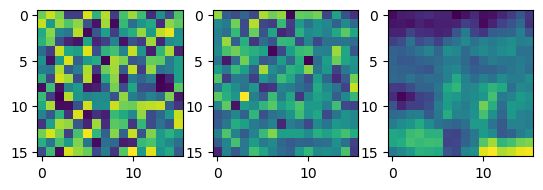

In [152]:
sampler = wrapper.get_sampler(kind='ODE')

feed1 = d_train[:4]

broke = 0.1*feed1 + 0.9*torch.rand_like(feed1)
#broke = feed1 + 2*torch.rand_like(feed1)
result = sampler(broke.repeat(1,1,1))
#for i in range(20):
#    result = sampler(result)
result = result.mean(1).detach().cpu()

vs = int(feed.shape[-1]**0.5)
for i in range(result.shape[0]):
    plt.subplot(1,3,1); plt.imshow(broke[i].cpu().view(vs,vs));
    plt.subplot(1,3,2); plt.imshow(result[i].cpu().view(vs,vs));
    plt.subplot(1,3,3); plt.imshow(feed1[i].cpu().view(vs,vs))
    print((feed1[i].cpu() - broke[i].cpu()).pow(2).mean(), (feed1[i].cpu() - result[i].cpu()).pow(2).mean())
    plt.show()
    